# Experiment 3 — Parameter-efficient fine-tuning of OmniAID v2's low-rank experts
**HIT401 Wildlife Deepfake Detection** · lightweight wildlife-domain adaptation of OmniAID v2

## 0. Experiment overview

**Question.** Can lightweight wildlife-domain adaptation reduce the remaining authentic-image, source-specific errors (in particular the iNaturalist false positives) while preserving OmniAID v2's very high synthetic-image detection?

**What is being compared.**

| | Model | Status |
|---|---|---|
| Before | Original OmniAID v2 (official checkpoint, off-the-shelf) | Complete: test accuracy 97.14%, 18 false positives (all iNaturalist) |
| After | The *same* OmniAID v2 checkpoint, fine-tuned on Dataset v1 TRAIN | This notebook |

**What changes.** Only OmniAID's own small trainable parts learn: the rank-1 low-rank experts inside every attention layer, the router that chooses experts, and the final real/fake output layer. Everything else in the network stays frozen. We use the official OmniAID training code (`main_finetune.py`, `engine_finetune.py`, `models/OmniAID.py`) and its official `--pretrained_checkpoint` route for training a pre-trained model on new data.

> Terminology: this is **parameter-efficient fine-tuning of OmniAID v2's low-rank experts**. It is *not* the separate official `OmniAID_LoRA` architecture, which cannot load the v2 checkpoint.

**Data roles (fixed before training).**

| Split | Images | Used for | Can it affect the final test result? |
|---|---|---|---|
| TRAIN | 3,319 | fine-tuning only | Yes, it is what the model learns from |
| VALIDATION | 693 | per-epoch evaluation, checkpoint selection, threshold selection | Yes, all decisions are made here |
| TEST | 664 | one final evaluation after everything is frozen | No, it is never used for any decision |

**Safety gates.** Training only runs when you set `RUN_TRAINING = True` in Stage 11. The final test only runs when model selection is frozen *and* you set `RUN_FINAL_TEST = True` in Stage 18. Test images are never copied into the training data folder.

**Checkpoint-selection rule (fixed before training, validation only).**
1. For each epoch, score all 693 validation images and compute balanced accuracy at that epoch's own validation Youden threshold.
2. Select the epoch with the highest validation balanced accuracy.
3. If epochs are effectively tied (difference < 0.001, i.e. less than the effect of one validation image), prefer higher validation fake recall.
4. If still tied, choose the earlier epoch.

**Threshold rule.** Youden's J statistic on the validation set, the same method as the baseline. The baseline threshold 0.359961 is *not* reused.

### Experiment configuration (the only cell you should edit)
Every value is labelled with where it comes from. **Verified-v2** values were read from the `args` saved *inside* the official v2 checkpoint, so they are the settings the checkpoint was actually trained with.

In [ ]:
# ---------- Architecture: must match the v2 checkpoint exactly (Verified-v2) ----------
ARCH = dict(
    CLIP_path="openai/clip-vit-large-patch14-336",   # Verified-v2 (same backbone; HF id instead of the authors' local path)
    num_experts=6,                 # Verified-v2 (5 routable semantic experts + 1 fixed artifact expert)
    rank_per_expert=1,             # Verified-v2 (also fixed by checkpoint tensor shapes)
    moe_top_k=2,                   # Verified-v2
    moe_router_hidden_dim=256,     # Verified-v2
    dropout=0.1,                   # Verified-v2 (active only during training; inference unaffected)
    moe_lambda_orth=0.001,         # Verified-v2
    moe_lambda_balance=0.001,      # Verified-v2
    moe_lambda_gating_cls=0.1,     # Verified-v2 (inactive here: our data has no semantic-domain labels)
    gradient_checkpointing_enable=False,  # Verified-v2 (set True only if the T4 runs out of memory)
)

# ---------- Training: official defaults unless labelled PROJECT ----------
TRAIN_CFG = dict(
    seed=0,              # official default and Verified-v2
    epochs=5,            # PROJECT choice (v2 used 1 epoch over millions of images); validation after every epoch
    batch_size=4,        # PROJECT choice for T4 memory (batch 8 ran out of memory in the Stage 10 probe; v2: 64 per GPU x 4 GPUs)
    update_freq=8,       # PROJECT choice: gradient accumulation -> effective batch 4 x 8 = 32 (unchanged)
    blr=2e-4,            # Verified-v2 base learning rate; official rule: lr = blr x effective_batch / 256
    opt="adamw",         # Verified-v2 / official default
    weight_decay=0.0,    # Verified-v2 / official default
    min_lr=1e-6,         # Verified-v2 / official default (half-cycle cosine schedule, per iteration)
    warmup_epochs=0,     # Verified-v2 / official default
    smoothing=0.1,       # Verified-v2 / official default (label smoothing)
    use_amp=True,        # PROJECT choice: official --use_amp flag, for T4 memory/speed (v2 itself trained in fp32)
    img_size=336,        # Verified-v2 and baseline
    num_workers=2,       # Colab CPU count
    training_mode="standard",  # official mode used with --pretrained_checkpoint: trains experts + router + head
)
EFFECTIVE_BATCH = TRAIN_CFG["batch_size"] * TRAIN_CFG["update_freq"]
LR = TRAIN_CFG["blr"] * EFFECTIVE_BATCH / 256
print(f"Effective batch = {EFFECTIVE_BATCH}  ->  learning rate = {LR:.2e} (official scaling rule)")

# If Stage 10 reports out-of-memory: set batch_size=4, update_freq=8 (same effective batch 32 and same LR).

# ---------- Fixed identities (do not edit) ----------
OMNIAID_REPO_URL = "https://github.com/yunncheng/OmniAID.git"
OMNIAID_COMMIT   = "40749406fbcd8893c11a160edf4a72a2d4dc7056"   # official HEAD since 2026-06-26; baseline clone (22 Sep) = this commit (inferred)
HF_REPO          = "Yunncheng/OmniAID"
HF_REVISION      = "279cae7398ac6636f46fc4668f755f11210b36bf"   # snapshot recorded in the baseline notebook output
HF_FILENAME      = "ckpt/checkpoint_omniaid_v2.pth"
BASELINE_THRESHOLD = 0.35996127128601074                          # baseline (for comparison only; not reused)

Effective batch = 32  ->  learning rate = 2.50e-05 (official scaling rule)


## 1. Mount Google Drive
**What:** connects Colab to the project Drive, where the frozen dataset, manifest and baseline evidence live.
**Data used:** none yet. **Affects final test result:** no.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
DRIVE_ROOT = Path("/content/drive/MyDrive/HIT401_Wildlife_Deepfake")
MANIFEST   = DRIVE_ROOT / "metadata" / "split_manifest.csv"
BASELINE_DIR = DRIVE_ROOT / "metadata" / "model_baseline"
OUT_DIR    = DRIVE_ROOT / "metadata" / "model_adaptation"          # evidence output (mirrors Verification_Evidence/model_adaptation)
CKPT_DIR   = OUT_DIR / "adapted_checkpoints"                         # small adapted-parameter files only (~6 MB each)
PLOTS_DIR  = OUT_DIR / "plots"
for d in (OUT_DIR, CKPT_DIR, PLOTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

REPO       = Path("/content/OmniAID_exp3")      # separate from the baseline's /content/OmniAID
LOCAL_DATA = Path("/content/exp3_data")         # local copy of TRAIN + VALIDATION only
TRAIN_DIR  = LOCAL_DATA / "train"
VAL_DIR    = LOCAL_DATA / "val"
for p in (DRIVE_ROOT, MANIFEST, BASELINE_DIR / "baseline_test_predictions.csv"):
    assert p.exists(), f"Missing: {p}"
print("Drive paths OK. Evidence will be written to:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive paths OK. Evidence will be written to: /content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/model_adaptation


## 2. Environment and dependency setup
**What:** installs the extra libraries the official training code imports. Colab's own PyTorch is kept, as it was for the baseline. `transformers` and `huggingface_hub` are pinned to the baseline versions.
**Data used:** none. **Affects final test result:** no.

In [ ]:
import subprocess, sys
pkgs = ["transformers==4.57.3", "huggingface_hub==0.36.0", "timm==1.0.10", "tensorboardx==2.6.4", "thop==0.1.1.post2209072238"]
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], capture_output=True, text=True)
print("pip returncode:", r.returncode)
if r.returncode != 0:
    print(r.stdout[-2000:], r.stderr[-2000:])

import torch, torchvision, transformers, timm, platform
assert torch.cuda.is_available(), "No GPU. Runtime > Change runtime type > T4 GPU."
print("GPU:", torch.cuda.get_device_name(0))
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| transformers", transformers.__version__, "| timm", timm.__version__)

pip returncode: 0
GPU: Tesla T4
torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | transformers 4.57.3 | timm 1.0.10


## 3. Locate the official OmniAID repository
**What:** clones the official repository into a *new* folder and pins it to the exact commit, so the baseline environment is not touched.
**Data used:** none. **Affects final test result:** no.

In [ ]:
import os
if not REPO.exists():
    subprocess.run(["git", "clone", "-q", OMNIAID_REPO_URL, str(REPO)], check=True)
subprocess.run(["git", "-C", str(REPO), "checkout", "-q", OMNIAID_COMMIT], check=True)
head = subprocess.run(["git", "-C", str(REPO), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
dirty = subprocess.run(["git", "-C", str(REPO), "status", "--porcelain"], capture_output=True, text=True).stdout.strip()
assert head == OMNIAID_COMMIT, head
assert dirty == "", "Official repository has local modifications; it must be unmodified."
for f in ["main_finetune.py", "engine_finetune.py", "models/OmniAID.py", "data/datasets.py", "reward/omniaid.py", "reward/clean_test.py"]:
    assert (REPO / f).exists(), f
print("Official OmniAID repository at commit", head, "(unmodified)")

Official OmniAID repository at commit 40749406fbcd8893c11a160edf4a72a2d4dc7056 (unmodified)


## 4. Record repository commit, checkpoint identity and environment
**What:** downloads the *same* v2 checkpoint snapshot used by the baseline, records its SHA-256 fingerprint, and re-reads the training settings stored inside it. This confirms the architecture values in the configuration cell.
**Data used:** none. **Affects final test result:** no.

In [ ]:
import hashlib, json, datetime, time
from huggingface_hub import hf_hub_download

BASE_CKPT = hf_hub_download(repo_id=HF_REPO, filename=HF_FILENAME, revision=HF_REVISION)
print("Base checkpoint:", BASE_CKPT, os.path.getsize(BASE_CKPT), "bytes")

t0 = time.time()
h = hashlib.sha256()
with open(BASE_CKPT, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 24), b""):
        h.update(chunk)
BASE_CKPT_SHA256 = h.hexdigest()
print(f"SHA-256: {BASE_CKPT_SHA256}  ({time.time()-t0:.0f}s)")

# Read the training arguments stored inside the checkpoint (memory-mapped; not loaded into RAM)
ck = torch.load(BASE_CKPT, map_location="cpu", weights_only=False, mmap=True)
ck_args = vars(ck["args"])
print("Checkpoint top-level keys:", list(ck.keys()), "| trained with training_mode =", ck_args["training_mode"])
mismatch = {k: (v, ck_args.get(k)) for k, v in ARCH.items() if k != "CLIP_path" and ck_args.get(k) != v}
assert not mismatch, f"ARCH differs from the checkpoint's own settings: {mismatch}"
print("ARCH matches the settings stored in the v2 checkpoint.")
print("Settings the v2 recipe used:", {k: ck_args[k] for k in ["blr", "lr", "batch_size", "world_size", "epochs", "smoothing", "weight_decay", "opt", "min_lr", "warmup_epochs", "use_amp", "seed", "img_size"]})
V2_CKPT_ARGS = {k: (v if isinstance(v, (int, float, str, bool, type(None), list, dict)) else str(v)) for k, v in ck_args.items()}
del ck

env = {
    "date": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": sys.version, "torch": torch.__version__, "torchvision": torchvision.__version__,
    "transformers": transformers.__version__, "timm": timm.__version__, "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
    "omniaid_repo": OMNIAID_REPO_URL, "omniaid_commit": head,
    "base_checkpoint_hf": f"{HF_REPO}@{HF_REVISION}:{HF_FILENAME}",
    "base_checkpoint_sha256": BASE_CKPT_SHA256,
    "fine_tuning_source": "official OmniAID main_finetune.py --pretrained_checkpoint (training_mode=standard); not OmniAID_LoRA",
}
with open(OUT_DIR / "environment_record.txt", "w") as f:
    for k, v in env.items():
        f.write(f"{k}: {v}\n")
with open(OUT_DIR / "v2_checkpoint_training_args.json", "w") as f:
    json.dump(V2_CKPT_ARGS, f, indent=1)
print(open(OUT_DIR / "environment_record.txt").read())

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Base checkpoint: /root/.cache/huggingface/hub/models--Yunncheng--OmniAID/snapshots/279cae7398ac6636f46fc4668f755f11210b36bf/ckpt/checkpoint_omniaid_v2.pth 3241518989 bytes
SHA-256: 919338928cab88cef1e6e4b85777749c74bdff6a1796fcd7e43a91422327f906  (26s)
Checkpoint top-level keys: ['model', 'optimizer', 'epoch', 'scaler', 'args'] | trained with training_mode = stage2_router_training
ARCH matches the settings stored in the v2 checkpoint.
Settings the v2 recipe used: {'blr': 0.0002, 'lr': 0.0002, 'batch_size': 64, 'world_size': 4, 'epochs': 1, 'smoothing': 0.1, 'weight_decay': 0.0, 'opt': 'adamw', 'min_lr': 1e-06, 'warmup_epochs': 0, 'use_amp': False, 'seed': 0, 'img_size': 336}
date: 2026-09-24T08:46:54
python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
torch: 2.11.0+cu128
torchvision: 0.26.0+cu128
transformers: 4.57.3
timm: 1.0.10
cuda: 12.8
gpu: Tesla T4
omniaid_repo: https://github.com/yunncheng/OmniAID.git
omniaid_commit: 40749406fbcd8893c11a160edf4a72a2d4dc7056
base_checkpoin

## 5. Load the frozen Dataset v1 manifest
**What:** reads the frozen split manifest. The split is **not** changed.
**Data used:** manifest only (no images). **Affects final test result:** no.

In [ ]:
import pandas as pd, numpy as np
manifest = pd.read_csv(MANIFEST)
manifest["filename"] = manifest["local_path"].map(lambda p: os.path.basename(p))
SPLIT_DIR = {"train": "train", "val": "validation", "test": "test"}
train_m = manifest[manifest.split == "train"].reset_index(drop=True)
val_m   = manifest[manifest.split == "val"].reset_index(drop=True)
test_ids = set(manifest.loc[manifest.split == "test", "image_id"])      # used only for leakage assertions
test_files = set(manifest.loc[manifest.split == "test", "filename"])
print("Manifest rows:", len(manifest))

Manifest rows: 4676


## 6. Verify split counts and prepare TRAIN and VALIDATION
**What:** checks the frozen split, then copies **only TRAIN and VALIDATION** images from the physical `final/` folders into a local training folder. The official loader expects the subfolder names `0_real` and `1_fake`. Test images are never copied, which makes test leakage during training physically impossible.
**Data used:** TRAIN + VALIDATION images. **Affects final test result:** no.

In [ ]:
import shutil
from collections import Counter

# --- frozen split checks (no changes are made) ---
assert manifest.image_id.is_unique and manifest.filename.is_unique
c = Counter(zip(manifest.split, manifest.label))
expected = {("train","real"):1668, ("train","fake"):1651, ("val","real"):363, ("val","fake"):330, ("test","real"):334, ("test","fake"):330}
assert dict(c) == expected, c
assert manifest.split.value_counts().to_dict() == {"train":3319, "val":693, "test":664}
nr = manifest[manifest.visual_qc_status == "NOT_REVIEWED"]
assert len(nr) == 206 and set(nr.split) == {"train"}, "NOT_REVIEWED images must be TRAIN only"
assert set(manifest.loc[manifest.label=="real","source"]) == {"Caltech","iNaturalist"}
assert set(manifest.loc[manifest.label=="fake","style"]) == {"community","camera_day","camera_night_ir"}
assert manifest.category.nunique() == 7
print("Frozen split verified: TRAIN 3,319 (1,668 real / 1,651 fake), VALIDATION 693, TEST 664; 206 NOT_REVIEWED in TRAIN only.")

# --- local copy of TRAIN and VALIDATION only ---
def build_local(split_df, split_key, dst_root):
    n = 0
    for _, row in split_df.iterrows():
        src = DRIVE_ROOT / "final" / SPLIT_DIR[split_key] / row.label / row.filename
        dst = dst_root / ("0_real" if row.label == "real" else "1_fake") / row.filename
        dst.parent.mkdir(parents=True, exist_ok=True)
        if not dst.exists():
            shutil.copy2(src, dst)
        n += 1
    return n

t0 = time.time()
build_local(train_m, "train", TRAIN_DIR)
build_local(val_m, "val", VAL_DIR)
print(f"Local copy done in {time.time()-t0:.0f}s")

def folder_files(root):
    return {sub: sorted(os.listdir(root / sub)) for sub in ("0_real", "1_fake")}
tr, va = folder_files(TRAIN_DIR), folder_files(VAL_DIR)
assert (len(tr["0_real"]), len(tr["1_fake"])) == (1668, 1651)
assert (len(va["0_real"]), len(va["1_fake"])) == (363, 330)
assert set(tr["0_real"] + tr["1_fake"]) == set(train_m.filename)
assert set(va["0_real"] + va["1_fake"]) == set(val_m.filename)
local_all = set(tr["0_real"] + tr["1_fake"] + va["0_real"] + va["1_fake"])
assert not (local_all & test_files), "LEAKAGE: a TEST image is in the local training data"
print("Local TRAIN: 1,668 real + 1,651 fake | Local VALIDATION: 363 real + 330 fake | TEST images present: 0")

Frozen split verified: TRAIN 3,319 (1,668 real / 1,651 fake), VALIDATION 693, TEST 664; 206 NOT_REVIEWED in TRAIN only.
Local copy done in 1s
Local TRAIN: 1,668 real + 1,651 fake | Local VALIDATION: 363 real + 330 fake | TEST images present: 0


## 7. Load the pretrained OmniAID v2 checkpoint (compatibility check)
**What:** this is the read-only compatibility test, and it must pass before anything else runs.
1. **7a** reproduces the baseline's own loading (`reward/omniaid.py` class, `strict=False`) and lists exactly which keys that load ignored.
2. **7b** builds the model with the official training code, compares every checkpoint key and tensor shape, and loads it with `strict=True`, exactly as the official `--pretrained_checkpoint` route does.
3. **7c** scores VALIDATION with the unmodified model and checks that it reproduces the baseline's recorded validation results (means 0.0960 / 0.7373, threshold 0.359961).

**Data used:** VALIDATION (7c only, as a sanity check; no decision is made). **Affects final test result:** no. No training happens here.

In [ ]:
# ---------- 7a. What did the baseline's strict=False load ignore? (CPU, then freed) ----------
import types, importlib, gc
sys.path.insert(0, str(REPO / "reward"))
baseline_mod = importlib.import_module("omniaid")          # the class the baseline used (reward/omniaid.py)
cfg = types.SimpleNamespace(CLIP_path=ARCH["CLIP_path"], num_experts=6, rank_per_expert=1, moe_top_k=2,
                            moe_router_hidden_dim=256, is_hybrid=True)   # = reward/clean_test.py BACKBONES["clip"]
bmodel = baseline_mod.OmniAID(cfg)
ck = torch.load(BASE_CKPT, map_location="cpu", weights_only=False, mmap=True)
sd = ck["model"] if "model" in ck else ck
sd = {k[len("module."):] if k.startswith("module.") else k: v for k, v in sd.items()}
res = bmodel.load_state_dict(sd, strict=False)       # raises on any shape mismatch
BASELINE_LOAD = {"missing_keys": list(res.missing_keys), "unexpected_keys": list(res.unexpected_keys)}
print("Baseline-style load (strict=False): missing =", len(res.missing_keys), "| unexpected =", len(res.unexpected_keys))
print("  missing:", res.missing_keys[:10], "\n  unexpected:", res.unexpected_keys[:10])
del bmodel, ck, sd; gc.collect()
sys.path.remove(str(REPO / "reward")); sys.modules.pop("omniaid", None)

Baseline-style load (strict=False): missing = 0 | unexpected = 0
  missing: [] 
  unexpected: []


<module 'omniaid' from '/content/OmniAID_exp3/reward/omniaid.py'>

In [ ]:
# ---------- 7b. Official model + official --pretrained_checkpoint loading (strict=True) ----------
os.chdir(REPO); sys.path.insert(0, str(REPO))
import main_finetune, utils as omni_utils
from data.datasets import GenerativeImageDataset
from engine_finetune import train_one_epoch

RUN_DIR = Path("/content/exp3_run"); RUN_DIR.mkdir(exist_ok=True)
CFG_JSON = OUT_DIR / "config_omniaid_v2_recovered.json"   # the v2 config the README refers to but the repo lacks; recovered from the checkpoint
json.dump({**ARCH, "stage1_base_dir": "", "experts_map": {}}, open(CFG_JSON, "w"), indent=2)

parser = main_finetune.get_args_parser()
args = parser.parse_args([
    "--model", "OmniAID", "--img_size", str(TRAIN_CFG["img_size"]),
    "--batch_size", str(TRAIN_CFG["batch_size"]), "--update_freq", str(TRAIN_CFG["update_freq"]),
    "--epochs", str(TRAIN_CFG["epochs"]), "--blr", str(TRAIN_CFG["blr"]),
    "--opt", TRAIN_CFG["opt"], "--weight_decay", str(TRAIN_CFG["weight_decay"]),
    "--min_lr", str(TRAIN_CFG["min_lr"]), "--warmup_epochs", str(TRAIN_CFG["warmup_epochs"]),
    "--smoothing", str(TRAIN_CFG["smoothing"]), "--use_amp", str(TRAIN_CFG["use_amp"]),
    "--seed", str(TRAIN_CFG["seed"]), "--num_workers", str(TRAIN_CFG["num_workers"]),
    "--data_path", str(TRAIN_DIR), "--eval_data_path", str(VAL_DIR), "--output_dir", str(RUN_DIR),
    "--moe_config_path", str(CFG_JSON), "--is_hybrid", "True", "--training_mode", TRAIN_CFG["training_mode"],
    "--pretrained_checkpoint", BASE_CKPT, "--save_ckpt", "False", "--dist_eval", "False",
])
# exactly what official main() does with the MoE config file
for k, v in json.load(open(CFG_JSON)).items():
    if getattr(args, k, None) is None:
        setattr(args, k, v)

device = main_finetune.setup_for_training(args)            # official: seeds torch/numpy, single-GPU mode
model, model_without_ddp, model_ema, _ = main_finetune.create_model_and_ema(args, device)

ck = torch.load(args.pretrained_checkpoint, map_location="cpu", weights_only=False, mmap=True)
ck_sd = ck["model"]
model_sd = model_without_ddp.state_dict()
missing    = sorted(set(model_sd) - set(ck_sd))
unexpected = sorted(set(ck_sd) - set(model_sd))
shape_mismatch = sorted(k for k in set(model_sd) & set(ck_sd) if tuple(model_sd[k].shape) != tuple(ck_sd[k].shape))
print(f"Checkpoint keys: {len(ck_sd)} | model keys: {len(model_sd)}")
print(f"Missing: {len(missing)} | Unexpected: {len(unexpected)} | Shape mismatches: {len(shape_mismatch)}")
COMPAT = {"checkpoint_keys": len(ck_sd), "model_keys": len(model_sd), "missing": missing,
          "unexpected": unexpected, "shape_mismatch": shape_mismatch, "baseline_strict_false_load": BASELINE_LOAD}
assert not (missing or unexpected or shape_mismatch), "MATERIAL INCOMPATIBILITY: stop and report"

model_without_ddp.load_state_dict(ck_sd, strict=True)       # official run_standard_training line
del ck, ck_sd, model_sd; gc.collect()
COMPAT["official_strict_true_load"] = "PASS"
json.dump(COMPAT, open(OUT_DIR / "checkpoint_compatibility.json", "w"), indent=1)
print("COMPATIBILITY: PASS (official strict=True load of the v2 checkpoint)")

# ---------- exact trainable / frozen parameters ----------
def group_of(name):
    if "_experts." in name: return "low-rank experts (U/S/V)"
    if name.startswith("gating_network"): return "router (gating network)"
    if name.startswith("head"): return "real/fake output layer (head)"
    if name.startswith("feature_extractor"): return "frozen routing CLIP copy"
    if ".mlp." in name: return "MLPs"
    if "layer_norm" in name or name.startswith(("ln_pre", "ln_post")): return "LayerNorms"
    if name.startswith("embeddings"): return "embeddings"
    if name.endswith(".bias") and "self_attn" in name: return "attention biases"
    return "other"
groups = {}
for n, p in model_without_ddp.named_parameters():
    g = groups.setdefault(group_of(n), {"trainable": 0, "frozen": 0})
    g["trainable" if p.requires_grad else "frozen"] += p.numel()
n_train = sum(p.numel() for p in model_without_ddp.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model_without_ddp.parameters())
n_buffers = sum(b.numel() for b in model_without_ddp.buffers())
print(pd.DataFrame(groups).T)
print(f"\nTrainable parameters: {n_train:,} of {n_total:,} ({100*n_train/n_total:.3f}%)")
print(f"(plus {n_buffers:,} frozen buffer values: main attention weights and SVD bases)")
TRAINABLE_GROUPS = sorted(g for g, v in groups.items() if v["trainable"])
assert TRAINABLE_GROUPS == sorted(["low-rank experts (U/S/V)", "router (gating network)", "real/fake output layer (head)"]), TRAINABLE_GROUPS
assert all(v["trainable"] == 0 for g, v in groups.items() if g not in TRAINABLE_GROUPS)
PARAM_COUNTS = {"trainable": n_train, "total": n_total, "percent_trainable": 100*n_train/n_total,
                "frozen_buffers": n_buffers, "by_group": groups}

🚨 Something went wrong trying to find the model name in the path: /usr/local/lib/python3.13/dist-packages/transformers/models/dinov3_vit/modular_dinov3_vit.py
🚨 Config not found for model. You can manually add it to HARDCODED_CONFIG_FOR_MODELS in utils/auto_docstring.py
🚨 Something went wrong trying to find the model name in the path: /usr/local/lib/python3.13/dist-packages/transformers/models/dinov3_vit/modular_dinov3_vit.py
🚨 Something went wrong trying to find the model name in the path: /usr/local/lib/python3.13/dist-packages/transformers/models/dinov3_vit/modular_dinov3_vit.py
🚨 Config not found for model. You can manually add it to HARDCODED_CONFIG_FOR_MODELS in utils/auto_docstring.py
🚨 Something went wrong trying to find the model name in the path: /usr/local/lib/python3.13/dist-packages/transformers/models/dinov3_vit/modular_dinov3_vit.py
🚨 Config not found for model. You can manually add it to HARDCODED_CONFIG_FOR_MODELS in utils/auto_docstring.py
🚨 Something went wrong tryin

In [ ]:
# ---------- 7c. Validation scoring function + baseline reproduction check ----------
from torch.utils.data import DataLoader
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score

fname2id_val = dict(zip(val_m.filename, val_m.image_id))

@torch.no_grad()
def score_folder(net, root, batch_size=16):
    # Official eval preprocessing (GenerativeImageDataset, is_train=False): Resize 336, ToTensor, CLIP normalisation.
    # fp32, eval mode (dropout off). Returns one row per image.
    ds = GenerativeImageDataset(root=str(root), is_train=False, resolution=args.img_size, model_name=args.model)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=TRAIN_CFG["num_workers"])
    net.eval()
    rows = []
    for x, y, paths, _ in dl:
        out = net(x.to(device))
        logits = out["cls"].float().cpu(); prob = out["prob"].float().cpu()
        for pth, yy, pr, lg in zip(paths, y.tolist(), prob.tolist(), logits.tolist()):
            rows.append({"filename": os.path.basename(pth), "y_true": yy, "score": pr, "logit_real": lg[0], "logit_fake": lg[1]})
    return pd.DataFrame(rows)

def youden(y, s):
    fpr, tpr, thr = roc_curve(y, s)
    i = int(np.argmax(tpr - fpr))
    return float(thr[i]), float(tpr[i]), float(fpr[i])

def val_metrics(df):
    y, s = df.y_true.values, df.score.values
    thr, tpr, fpr = youden(y, s)
    pred = (s >= thr).astype(int)
    fake_recall = ((pred == 1) & (y == 1)).sum() / (y == 1).sum()
    real_recall = ((pred == 0) & (y == 0)).sum() / (y == 0).sum()
    ce = torch.nn.functional.cross_entropy(torch.tensor(df[["logit_real", "logit_fake"]].values), torch.tensor(y)).item()
    return {"val_threshold_youden": thr, "val_balanced_accuracy": (fake_recall + real_recall) / 2,
            "val_accuracy": float((pred == y).mean()), "val_fake_recall": float(fake_recall), "val_real_recall": float(real_recall),
            "val_roc_auc": float(roc_auc_score(y, s)), "val_ap": float(average_precision_score(y, s)),
            "val_ce_loss": ce, "val_mean_score_real": float(s[y == 0].mean()), "val_mean_score_fake": float(s[y == 1].mean()),
            "val_accuracy_at_0.5": float(((s >= 0.5).astype(int) == y).mean())}

t0 = time.time()
val0 = score_folder(model_without_ddp, VAL_DIR)
val0["image_id"] = val0.filename.map(fname2id_val)
assert len(val0) == 693 and val0.image_id.notna().all()
m0 = val_metrics(val0)
print(f"Validation scored in {time.time()-t0:.0f}s")
print(f"Unmodified v2 on VALIDATION: mean REAL={m0['val_mean_score_real']:.4f} FAKE={m0['val_mean_score_fake']:.4f} "
      f"threshold={m0['val_threshold_youden']:.6f} TPR={m0['val_fake_recall']:.4f} FPR={1-m0['val_real_recall']:.4f}")
print("Baseline recorded:           mean REAL=0.0960 FAKE=0.7373 threshold=0.359961 TPR=0.9909 FPR=0.0193")
repro_ok = (abs(m0["val_mean_score_real"] - 0.0960) < 0.002 and abs(m0["val_mean_score_fake"] - 0.7373) < 0.002
            and abs(m0["val_threshold_youden"] - BASELINE_THRESHOLD) < 0.01)
assert repro_ok, "The loaded model does not reproduce the baseline on validation: stop and investigate before training."
val0.to_csv(OUT_DIR / "validation_predictions_epoch0_unadapted.csv", index=False)
EPOCH0 = {"epoch": 0, **m0}
print("Baseline reproduction on VALIDATION: PASS (epoch-0 reference row; not a selection candidate)")

Recursively scanning for data in: /content/exp3_data/val
 - Real folder: '0_real', Fake folder: '1_fake'
Found 693 images:
 - Real images: 363
 - Fake images: 330
 - Real/Fake ratio: 52.38%/47.62%
Validation scored in 190s
Unmodified v2 on VALIDATION: mean REAL=0.0960 FAKE=0.7373 threshold=0.359961 TPR=0.9909 FPR=0.0193
Baseline recorded:           mean REAL=0.0960 FAKE=0.7373 threshold=0.359961 TPR=0.9909 FPR=0.0193
Baseline reproduction on VALIDATION: PASS (epoch-0 reference row; not a selection candidate)


## 8. Configure the official parameter-efficient fine-tuning
**What:** creates the official optimizer (AdamW over trainable parameters only), the official loss (label smoothing 0.1) and the official mixed-precision scaler, then saves the full configuration as evidence.
**Data used:** none. **Affects final test result:** no.

In [ ]:
optimizer, criterion, loss_scaler, mixup_fn = main_finetune.create_optimizer_criterion_scaler(args, model_without_ddp)
assert abs(args.lr - LR) < 1e-12, (args.lr, LR)
assert mixup_fn is None
n_opt = sum(p.numel() for g in optimizer.param_groups for p in g["params"])
assert n_opt == PARAM_COUNTS["trainable"], "Optimizer must hold exactly the trainable parameters"

adaptation_config = {
    "experiment": "Experiment 3: parameter-efficient fine-tuning of OmniAID v2's low-rank experts",
    "method": "official OmniAID main_finetune.py route (--model OmniAID --pretrained_checkpoint, training_mode=standard); "
              "official create_model_and_ema, create_optimizer_criterion_scaler, create_dataloaders and engine_finetune.train_one_epoch. "
              "Project wrapper replaces only the outer epoch loop: validation-only scoring each epoch, and saving of adapted parameters "
              "instead of full 3 GB checkpoints.",
    "omniaid_commit": OMNIAID_COMMIT, "base_checkpoint": f"{HF_REPO}@{HF_REVISION}:{HF_FILENAME}",
    "base_checkpoint_sha256": BASE_CKPT_SHA256,
    "architecture_verified_from_checkpoint_args": ARCH,
    "training": {**TRAIN_CFG, "effective_batch": EFFECTIVE_BATCH, "lr": args.lr,
                 "optimizer_steps_per_epoch": (3319 // TRAIN_CFG["batch_size"]) // TRAIN_CFG["update_freq"],
                 "scheduler": "official half-cycle cosine per iteration (utils.adjust_learning_rate), no warmup",
                 "loss": "official get_losses: label-smoothed CE (0.1) + 0.001*orthogonality + 0.001*router balance (+ gating CE, inactive)",
                 "sampler": "official DistributedSampler(shuffle=True, seed=0); set_epoch(epoch) called each epoch as in the official multi-GPU run",
                 "drop_last": True},
    "value_sources": {"Verified-v2": "read from args stored inside the official v2 checkpoint",
                      "PROJECT": ["epochs=5", "batch_size=4 (batch 8 ran out of T4 memory in the Stage 10 probe)", "update_freq=8 (effective batch 32, unchanged)", "use_amp=True", "num_workers=2"]},
    "parameters": PARAM_COUNTS,
    "trainable_modules": TRAINABLE_GROUPS,
    "frozen_modules": sorted(g for g in PARAM_COUNTS["by_group"] if g not in TRAINABLE_GROUPS) + ["buffers: main attention weights, SVD bases"],
    "preprocessing": "Resize(336,336) + ToTensor + CLIP mean/std (official v2 single-resize pipeline; identical to baseline); no augmentation",
    "checkpoint_selection_rule": "VALIDATION only: highest balanced accuracy at each epoch's own Youden threshold; "
                                 "if |difference| < 0.001 prefer higher validation fake recall; if still tied, earlier epoch",
    "threshold_selection_rule": "Youden's J on VALIDATION scores of the selected (reloaded) model; frozen before TEST",
    "test_policy": "TEST never copied locally, never used for any decision; evaluated once after freezing",
}
json.dump(adaptation_config, open(OUT_DIR / "adaptation_config.json", "w"), indent=2, default=str)
print(json.dumps(adaptation_config["training"], indent=1))

base lr: 2.00e-04
actual lr: 2.50e-05
accumulate grad iterations: 8
effective batch size: 32
Criterion: LabelSmoothingCrossEntropy()
{
 "seed": 0,
 "epochs": 5,
 "batch_size": 4,
 "update_freq": 8,
 "blr": 0.0002,
 "opt": "adamw",
 "weight_decay": 0.0,
 "min_lr": 1e-06,
 "warmup_epochs": 0,
 "smoothing": 0.1,
 "use_amp": true,
 "img_size": 336,
 "num_workers": 2,
 "training_mode": "standard",
 "effective_batch": 32,
 "lr": 2.5e-05,
 "optimizer_steps_per_epoch": 103,
 "scheduler": "official half-cycle cosine per iteration (utils.adjust_learning_rate), no warmup",
 "loss": "official get_losses: label-smoothed CE (0.1) + 0.001*orthogonality + 0.001*router balance (+ gating CE, inactive)",
 "sampler": "official DistributedSampler(shuffle=True, seed=0); set_epoch(epoch) called each epoch as in the official multi-GPU run",
 "drop_last": true
}


## 9. Build the TRAIN and VALIDATION loaders
**What:** builds the training loader with the official `create_dataloaders` function, which applies the official preprocessing. Validation images are scored separately by `score_folder` (Stage 7c).
**Data used:** TRAIN (loader), VALIDATION (folder). **Affects final test result:** no.

In [ ]:
dataset_train, data_loader_train, _, _ = main_finetune.create_dataloaders(args, load_train=True, load_val=False)
labels = [d["label"] for d in dataset_train.data_list]
assert len(dataset_train) == 3319 and labels.count(0) == 1668 and labels.count(1) == 1651
assert not ({os.path.basename(d["image_path"]) for d in dataset_train.data_list} & test_files)
print(f"TRAIN loader: {len(dataset_train)} images, {len(data_loader_train)} batches of {args.batch_size} "
      f"(drop_last=True, official) -> {len(data_loader_train)//args.update_freq} optimizer steps per epoch")

Attempting to list subfolders for path: /content/exp3_data/train
Found subdirectories in local path: ['0_real', '1_fake']
Recursively scanning for data in: /content/exp3_data/train
 - Real folder: '0_real', Fake folder: '1_fake'
Found 3319 images:
 - Real images: 1668
 - Fake images: 1651
 - Real/Fake ratio: 50.26%/49.74%
TRAIN loader: 3319 images, 829 batches of 4 (drop_last=True, official) -> 103 optimizer steps per epoch


## 10. Training configuration summary and T4 memory probe
**What:** prints the final configuration and runs **one** forward and backward pass to measure GPU memory. The weights are **not** updated (no optimizer step), and random seeds are reset before training. If memory is too high, change `batch_size` / `update_freq` in the configuration cell (for example 4 / 8) and re-run from Stage 7b.
**Data used:** one TRAIN batch. **Affects final test result:** no.

In [ ]:
from contextlib import nullcontext
print(f"Model: OmniAID v2 (CLIP ViT-L/14 @ 336) | trainable {PARAM_COUNTS['trainable']:,} / {PARAM_COUNTS['total']:,} "
      f"({PARAM_COUNTS['percent_trainable']:.3f}%)")
print(f"Epochs {args.epochs} | batch {args.batch_size} x accumulation {args.update_freq} = effective {EFFECTIVE_BATCH} | "
      f"lr {args.lr:.2e} | AdamW wd {args.weight_decay} | cosine to {args.min_lr} | label smoothing {args.smoothing} | AMP {args.use_amp}")

torch.cuda.reset_peak_memory_stats()
x, y, _, cat = next(iter(data_loader_train))
model.train()
with (torch.cuda.amp.autocast() if args.use_amp else nullcontext()):
    out = model(x.to(device))
    loss = model_without_ddp.get_losses(out, y.to(device), cat.to(device), criterion)["overall_loss"]
loss.backward()
optimizer.zero_grad(set_to_none=True)
peak = torch.cuda.max_memory_allocated() / 2**30
total = torch.cuda.get_device_properties(0).total_memory / 2**30
print(f"Probe loss {loss.item():.4f} | peak GPU memory {peak:.1f} GiB of {total:.1f} GiB")
del x, y, cat, out, loss; torch.cuda.empty_cache()
if peak > 0.9 * total:
    print("WARNING: close to the memory limit. Use batch_size=4, update_freq=8 (same effective batch and lr).")

Model: OmniAID v2 (CLIP ViT-L/14 @ 336) | trainable 1,445,959 / 507,797,575 (0.285%)
Epochs 5 | batch 4 x accumulation 8 = effective 32 | lr 2.50e-05 | AdamW wd 0.0 | cosine to 1e-06 | label smoothing 0.1 | AMP True
Probe loss 0.2652 | peak GPU memory 12.9 GiB of 14.6 GiB


---
### START EXPERIMENT 3 TRAINING
---
## 11. Run the parameter-efficient fine-tuning
**What:** trains for up to 5 epochs with the official `train_one_epoch`. After **each** epoch it:
* scores all 693 VALIDATION images (fp32, eval mode);
* records validation metrics;
* saves only the adapted parameters (experts, router, head, about 6 MB) plus the optimizer state for resuming.

The 3 GB base checkpoint is never duplicated. Everything is written to Drive after every epoch, so a Colab disconnect loses at most one epoch. To resume, re-run Stages 1–10 and then this cell; it continues from the last completed epoch.

**Data used:** TRAIN (learning) + VALIDATION (measurement). **Affects final test result:** yes, this creates the candidate models. TEST is not used.

Set `RUN_TRAINING = True` to start. **Expected time:** roughly 20–30 minutes per epoch on a T4 (this is an estimate).

In [ ]:
RUN_TRAINING = True       # set True by the operator after Stages 0-10 passed (batch 4 x 8)

assert RUN_TRAINING, "Training not started. Set RUN_TRAINING = True after reviewing Stages 0-10."
import random, csv as _csv
HIST_CSV = OUT_DIR / "training_history.csv"
LOG_TXT = OUT_DIR / "training_log.txt"

def log(msg):
    line = f"[{datetime.datetime.now().isoformat(timespec='seconds')}] {msg}"
    print(line)
    with open(LOG_TXT, "a") as f:
        f.write(line + "\n")

def adapted_state(net):
    return {n: p.detach().cpu().clone() for n, p in net.named_parameters() if p.requires_grad}

# resume support
done = sorted(int(p.stem.split("_")[-1]) for p in CKPT_DIR.glob("resume_epoch_*.pt"))
start_epoch = (done[-1] + 1) if done else 0
history = pd.read_csv(HIST_CSV).to_dict("records") if (start_epoch > 0 and HIST_CSV.exists()) else [EPOCH0]
if start_epoch > 0:
    r = torch.load(CKPT_DIR / f"resume_epoch_{done[-1]}.pt", map_location="cpu")
    a = torch.load(CKPT_DIR / f"adapted_epoch_{done[-1]}.pt", map_location="cpu")
    model_without_ddp.load_state_dict(a["adapted_state"], strict=False)
    optimizer.load_state_dict(r["optimizer"]); loss_scaler.load_state_dict(r["scaler"])
    log(f"Resuming after epoch {done[-1]}")
else:
    log(f"Start: {adaptation_config['experiment']} | effective batch {EFFECTIVE_BATCH} | lr {args.lr:.2e} | epochs {args.epochs}")

# reset seeds after the memory probe so training is reproducible
torch.manual_seed(args.seed + start_epoch); np.random.seed(args.seed + start_epoch); random.seed(args.seed + start_epoch)

for epoch in range(start_epoch, args.epochs):
    data_loader_train.sampler.set_epoch(epoch)
    t0 = time.time()
    train_stats = train_one_epoch(model, criterion, data_loader_train, optimizer, device, epoch, loss_scaler,
                                  args.clip_grad, model_ema, mixup_fn, log_writer=None, args=args)   # OFFICIAL training step
    train_time = time.time() - t0

    t1 = time.time()
    vdf = score_folder(model_without_ddp, VAL_DIR)
    vdf["image_id"] = vdf.filename.map(fname2id_val)
    vm = val_metrics(vdf)
    val_time = time.time() - t1

    ep = epoch + 1   # epochs numbered 1..5 (0 = unadapted reference)
    vdf.to_csv(OUT_DIR / f"validation_predictions_epoch{ep}.csv", index=False)
    st = adapted_state(model_without_ddp)
    torch.save({"adapted_state": st, "epoch": ep, "base_checkpoint_sha256": BASE_CKPT_SHA256,
                "base_checkpoint": f"{HF_REPO}@{HF_REVISION}:{HF_FILENAME}", "omniaid_commit": OMNIAID_COMMIT,
                "arch": ARCH, "train_cfg": TRAIN_CFG}, CKPT_DIR / f"adapted_epoch_{epoch}.pt")
    torch.save({"optimizer": optimizer.state_dict(), "scaler": loss_scaler.state_dict(), "epoch": epoch},
               CKPT_DIR / f"resume_epoch_{epoch}.pt")

    row = {"epoch": ep, "train_loss": train_stats.get("overall_loss"), "train_cls_loss": train_stats.get("classification_loss"),
           "train_orth_loss": train_stats.get("orth_loss"), "train_balance_loss": train_stats.get("balance_loss"),
           "train_class_acc": train_stats.get("class_acc"), "lr_end": train_stats.get("lr"), **vm,
           "train_seconds": round(train_time), "val_seconds": round(val_time),
           "gpu": torch.cuda.get_device_name(0), "peak_gpu_gib": round(torch.cuda.max_memory_allocated() / 2**30, 2),
           "trainable_params": PARAM_COUNTS["trainable"], "total_params": PARAM_COUNTS["total"]}
    history.append(row)
    pd.DataFrame(history).to_csv(HIST_CSV, index=False)
    log(f"Epoch {ep}: train_loss {row['train_loss']:.4f} | VAL bal_acc {vm['val_balanced_accuracy']:.4f} "
        f"fake_recall {vm['val_fake_recall']:.4f} real_recall {vm['val_real_recall']:.4f} AUC {vm['val_roc_auc']:.4f} "
        f"| {train_time/60:.1f} + {val_time/60:.1f} min")

log("Training complete.")

[2026-09-24T09:02:07] Start: Experiment 3: parameter-efficient fine-tuning of OmniAID v2's low-rank experts | effective batch 32 | lr 2.50e-05 | epochs 5
Epoch: [0]  [  0/829]  eta: 1:33:11  lr: 0.000025  overall_loss: 0.0332 (0.0332)  classification_loss: 0.2591 (0.2591)  orth_loss: 1.1756 (1.1756)  balance_loss: 4.9705 (4.9705)  gating_cls_loss: 0.0000 (0.0000)  class_acc: 1.0000 (1.0000)  min_lr: 0.0000 (0.0000)  time: 6.7448  data: 0.3576  max mem: 13206
Epoch: [0]  [ 20/829]  eta: 0:38:16  lr: 0.000025  overall_loss: 0.0374 (0.0416)  classification_loss: 0.2930 (0.3266)  orth_loss: 1.1756 (1.1756)  balance_loss: 4.8820 (4.7577)  gating_cls_loss: 0.0000 (0.0000)  class_acc: 1.0000 (0.9524)  min_lr: 0.0000 (0.0000)  grad_norm: 3.3396 (5.8300)  time: 2.6436  data: 0.0004  max mem: 13235
Epoch: [0]  [ 40/829]  eta: 0:35:23  lr: 0.000025  overall_loss: 0.0314 (0.0381)  classification_loss: 0.2460 (0.2991)  orth_loss: 1.1755 (1.1755)  balance_loss: 4.8567 (4.7317)  gating_cls_loss: 0.00

## 12. Training history
**What:** shows and plots the per-epoch record. Epoch 0 is the unadapted model, shown for reference only.
**Data used:** saved results. **Affects final test result:** no.

,epoch,train_loss,val_ce_loss,val_balanced_accuracy,val_fake_recall,val_real_recall,val_roc_auc,val_threshold_youden,lr_end
0,0,NaN,0.210609,0.985813,0.990909,0.980716,0.997112,0.359961,NaN
1,1,0.030346,0.058687,0.998623,1.000000,0.997245,0.999992,0.502637,0.000024
2,2,0.027379,0.054076,1.000000,1.000000,1.000000,1.000000,0.584899,0.000020
3,3,0.026936,0.053844,1.000000,1.000000,1.000000,1.000000,0.580252,0.000013
4,4,0.026814,0.052128,1.000000,1.000000,1.000000,1.000000,0.630119,0.000006
5,5,0.026734,0.052396,1.000000,1.000000,1.000000,1.000000,0.621521,0.000002


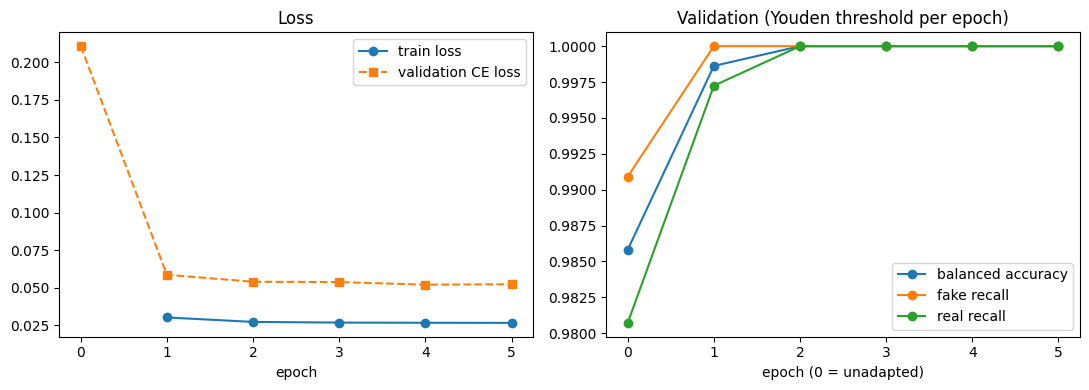

In [ ]:
import matplotlib.pyplot as plt
hist = pd.read_csv(OUT_DIR / "training_history.csv")
display(hist[["epoch", "train_loss", "val_ce_loss", "val_balanced_accuracy", "val_fake_recall", "val_real_recall", "val_roc_auc", "val_threshold_youden", "lr_end"]])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
h = hist[hist.epoch > 0]
ax[0].plot(h.epoch, h.train_loss, "o-", label="train loss"); ax[0].plot(hist.epoch, hist.val_ce_loss, "s--", label="validation CE loss")
ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].set_title("Loss")
for col, lab in [("val_balanced_accuracy", "balanced accuracy"), ("val_fake_recall", "fake recall"), ("val_real_recall", "real recall")]:
    ax[1].plot(hist.epoch, hist[col], "o-", label=lab)
ax[1].set_xlabel("epoch (0 = unadapted)"); ax[1].set_title("Validation (Youden threshold per epoch)"); ax[1].legend()
plt.tight_layout(); plt.savefig(PLOTS_DIR / "training_curve.png", dpi=150); plt.show()

## 13. Saved checkpoints
**What:** lists the adapted-parameter files with their SHA-256 fingerprints.
**Data used:** none. **Affects final test result:** no.

In [ ]:
def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 24), b""):
            h.update(chunk)
    return h.hexdigest()
ckpts = sorted(CKPT_DIR.glob("adapted_epoch_*.pt"), key=lambda p: int(p.stem.split("_")[-1]))
for p in ckpts:
    print(f"{p.name}: {p.stat().st_size/2**20:.1f} MB  sha256 {sha256_file(p)[:16]}...")

## 14. Select the best checkpoint (VALIDATION only)
**What:** applies the pre-defined rule to the validation results of epochs 1–5.
**Data used:** VALIDATION results only. **Affects final test result:** yes, it chooses the model. TEST is not used.

In [ ]:
cand = pd.read_csv(OUT_DIR / "training_history.csv")
cand = cand[cand.epoch > 0].copy()           # epoch 0 (unadapted) is a reference, not a candidate
best_bal = cand.val_balanced_accuracy.max()
tied = cand[cand.val_balanced_accuracy >= best_bal - 0.001]                 # rule 3: effectively tied
tied = tied[tied.val_fake_recall == tied.val_fake_recall.max()]             # prefer higher fake recall
SELECTED_EPOCH = int(tied.epoch.min())                                      # rule 4: earlier epoch
sel_row = cand[cand.epoch == SELECTED_EPOCH].iloc[0]
SELECTED_FILE = CKPT_DIR / f"adapted_epoch_{SELECTED_EPOCH-1}.pt"
display(cand[["epoch", "val_balanced_accuracy", "val_fake_recall", "val_real_recall", "val_roc_auc"]])
print(f"Selected epoch {SELECTED_EPOCH}: balanced accuracy {sel_row.val_balanced_accuracy:.4f}, "
      f"fake recall {sel_row.val_fake_recall:.4f}, real recall {sel_row.val_real_recall:.4f}  ({SELECTED_FILE.name})")

## 15. Rebuild the selected model and score the full validation set
**What:** frees the training model, then rebuilds the adapted model **from scratch** as base v2 checkpoint (SHA-256 checked) + saved adapted parameters. It re-scores VALIDATION and confirms the predictions match the ones recorded during training. This proves the saved files alone reproduce the adapted model.
**Data used:** VALIDATION. **Affects final test result:** no (it is a verification).

In [ ]:
for _v in ("model", "model_without_ddp", "optimizer", "loss_scaler"):
    globals().pop(_v, None)
gc.collect(); torch.cuda.empty_cache()

def build_adapted_model(adapted_path):
    # Reconstruct: official OmniAID + base v2 checkpoint (strict) + adapted parameters.
    assert sha256_file(BASE_CKPT) == BASE_CKPT_SHA256, "Base checkpoint changed"
    a = torch.load(adapted_path, map_location="cpu")
    assert a["base_checkpoint_sha256"] == BASE_CKPT_SHA256
    m, m_wo, _, _ = main_finetune.create_model_and_ema(args, device)
    base = torch.load(BASE_CKPT, map_location="cpu", weights_only=False, mmap=True)
    m_wo.load_state_dict(base["model"], strict=True); del base
    sd = m_wo.state_dict()
    assert all(k in sd and sd[k].shape == v.shape for k, v in a["adapted_state"].items())
    res = m_wo.load_state_dict(a["adapted_state"], strict=False)
    assert not res.unexpected_keys
    assert set(sd) - set(res.missing_keys) == set(a["adapted_state"])
    m_wo.eval()
    return m_wo

final_model = build_adapted_model(SELECTED_FILE)
val_final = score_folder(final_model, VAL_DIR)
val_final["image_id"] = val_final.filename.map(fname2id_val)
recorded = pd.read_csv(OUT_DIR / f"validation_predictions_epoch{SELECTED_EPOCH}.csv")
cmp = val_final.merge(recorded, on="image_id", suffixes=("_reload", "_train"))
max_diff = float((cmp.score_reload - cmp.score_train).abs().max())
print(f"Reloaded vs in-training validation scores: n={len(cmp)}, max |difference| = {max_diff:.2e}")
assert len(cmp) == 693 and max_diff < 1e-5, "Reloaded model does not reproduce the trained model"
print("Reload reproducibility: PASS")

## 16. Select the adapted threshold (VALIDATION only)
**What:** checks the score direction, then chooses the adapted model's Real/Fake threshold with Youden's J, the same method as the baseline. The baseline threshold is not reused.
**Data used:** VALIDATION. **Affects final test result:** yes, it sets the decision threshold. TEST is not used.

In [ ]:
mv = val_metrics(val_final)
assert mv["val_mean_score_fake"] > mv["val_mean_score_real"], "Score orientation changed"
ADAPTED_THRESHOLD = mv["val_threshold_youden"]
print(f"Orientation: higher = more fake-like (mean REAL {mv['val_mean_score_real']:.4f}, FAKE {mv['val_mean_score_fake']:.4f})")
print(f"Adapted threshold (Youden's J on validation): {ADAPTED_THRESHOLD:.6f}   [baseline was {BASELINE_THRESHOLD:.6f}]")
val_out = val_final.merge(val_m[["image_id", "label", "source", "category", "style"]], on="image_id")
val_out["predicted_label"] = np.where(val_out.score >= ADAPTED_THRESHOLD, "fake", "real")
val_out.to_csv(OUT_DIR / "validation_predictions.csv", index=False)
json.dump({"selected_epoch": SELECTED_EPOCH, **mv}, open(OUT_DIR / "validation_metrics.json", "w"), indent=2)
open(OUT_DIR / "adapted_threshold.txt", "w").write(f"{ADAPTED_THRESHOLD!r}\n")

## 17. Freeze the selected checkpoint and threshold
**What:** writes a frozen record (checkpoint file, fingerprints, threshold, rules). Stage 18 refuses to run without it.
**Data used:** none. **Affects final test result:** it locks the choices before TEST.

In [ ]:
FROZEN = {
    "frozen_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "selected_epoch": SELECTED_EPOCH, "adapted_file": str(SELECTED_FILE), "adapted_file_sha256": sha256_file(SELECTED_FILE),
    "base_checkpoint_sha256": BASE_CKPT_SHA256, "omniaid_commit": OMNIAID_COMMIT,
    "adapted_threshold": ADAPTED_THRESHOLD, "threshold_rule": adaptation_config["threshold_selection_rule"],
    "selection_rule": adaptation_config["checkpoint_selection_rule"], "reload_max_abs_diff": max_diff,
}
json.dump(FROZEN, open(OUT_DIR / "frozen_selection.json", "w"), indent=2)
print(json.dumps(FROZEN, indent=1))

---
### FINAL TEST — DO NOT RUN UNTIL MODEL SELECTION IS COMPLETE
---
## 18. Evaluate the same 664-image frozen TEST split (once)
**What:** scores the frozen adapted model on the untouched TEST split, using the frozen threshold. It runs only if Stage 17 produced `frozen_selection.json` and you set `RUN_FINAL_TEST = True`. A lock file records that the test has been run.
**Data used:** TEST, for the first and only time. **Affects final test result:** this *is* the final test result.

In [21]:
RUN_FINAL_TEST = True    # set True by the operator after Stages 11-17 (frozen epoch 2, threshold 0.584899)

assert RUN_FINAL_TEST, "Final test not run. Set RUN_FINAL_TEST = True only after model selection is frozen."
FROZEN = json.load(open(OUT_DIR / "frozen_selection.json"))
LOCK = OUT_DIR / "TEST_EVALUATED.json"
assert not LOCK.exists(), f"TEST was already evaluated ({json.load(open(LOCK))}). Do not re-run."
assert sha256_file(FROZEN["adapted_file"]) == FROZEN["adapted_file_sha256"]
if "final_model" not in globals():
    final_model = build_adapted_model(Path(FROZEN["adapted_file"]))
T = FROZEN["adapted_threshold"]

# official loader needs 0_real / 1_fake folders: build a view of per-file symlinks to Drive final/test (files are not copied)
test_m = manifest[manifest.split == "test"].reset_index(drop=True)
TEST_VIEW = Path("/content/exp3_test_view")
for _, row in test_m.iterrows():
    link = TEST_VIEW / ("0_real" if row.label == "real" else "1_fake") / row.filename
    link.parent.mkdir(parents=True, exist_ok=True)
    if not link.exists():
        os.symlink(DRIVE_ROOT / "final" / "test" / row.label / row.filename, link)
tdf = score_folder(final_model, TEST_VIEW)
tdf = tdf.merge(test_m[["filename", "image_id", "label", "source", "category", "style"]], on="filename")
assert len(tdf) == 664 and tdf.image_id.is_unique
tdf["predicted_label"] = np.where(tdf.score >= T, "fake", "real")
tdf["correct"] = tdf.predicted_label == tdf.label
tdf.rename(columns={"score": "model_score", "label": "true_label"}).to_csv(OUT_DIR / "test_predictions.csv", index=False)
json.dump({"evaluated_at": datetime.datetime.now().isoformat(timespec="seconds"), "n": len(tdf),
           "adapted_file_sha256": FROZEN["adapted_file_sha256"], "threshold": T}, open(LOCK, "w"), indent=1)
print("TEST scored once: 664 predictions saved.")

Recursively scanning for data in: /content/exp3_test_view
 - Real folder: '0_real', Fake folder: '1_fake'
Found 664 images:
 - Real images: 334
 - Fake images: 330
 - Real/Fake ratio: 50.30%/49.70%
TEST scored once: 664 predictions saved.


## 19. Overall metrics
The same metrics and formulas as the baseline.

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
def overall(y_true, score, thr):
    y_pred = (score >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred),
            "fake_recall": tp/(tp+fn), "real_recall": tn/(tn+fp), "f1": f1_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, score), "average_precision": average_precision_score(y_true, score),
            "fpr": fp/(fp+tn), "fnr": fn/(fn+tp), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}
tdf["y_true"] = (tdf.label == "fake").astype(int)
adapted = overall(tdf.y_true.values, tdf.score.values, T)
json.dump({**adapted, "threshold": T, "n": len(tdf)}, open(OUT_DIR / "test_metrics.json", "w"), indent=2, default=float)
for k, v in adapted.items():
    print(f"{k:18s} {v:.4f}" if isinstance(v, float) else f"{k:18s} {v}")

accuracy           0.9985
precision          0.9970
fake_recall        1.0000
real_recall        0.9970
f1                 0.9985
roc_auc            1.0000
average_precision  1.0000
fpr                0.0030
fnr                0.0000
TN                 333
FP                 1
FN                 0
TP                 330


## 20. Subgroup metrics (same definitions as the baseline)

In [23]:
def subgroups(df, pred_col="predicted_label", label_col="label"):
    rows = []
    real, fake = df[df[label_col] == "real"], df[df[label_col] == "fake"]
    for g, s in real.groupby("source"):
        rows.append({"type": "authentic_source", "group": g, "n": len(s), "accuracy": float((s[pred_col] == "real").mean())})
    for g, s in fake.groupby("style"):
        rows.append({"type": "synthetic_style", "group": g, "n": len(s), "accuracy": float((s[pred_col] == "fake").mean())})
    for g, s in df.groupby("category"):
        yt = (s[label_col] == "fake").astype(int); yp = (s[pred_col] == "fake").astype(int)
        rows.append({"type": "category", "group": g, "n": len(s), "accuracy": accuracy_score(yt, yp),
                     "precision": precision_score(yt, yp, zero_division=0), "recall": recall_score(yt, yp, zero_division=0),
                     "f1": f1_score(yt, yp, zero_division=0)})
    return pd.DataFrame(rows)
sub_adapted = subgroups(tdf)
sub_adapted.to_csv(OUT_DIR / "subgroup_results.csv", index=False)
display(sub_adapted)

,type,group,n,accuracy,precision,recall,f1
0,authentic_source,Caltech,158,1.000000,NaN,NaN,NaN
1,authentic_source,iNaturalist,176,0.994318,NaN,NaN,NaN
2,synthetic_style,camera_day,87,1.000000,NaN,NaN,NaN
3,synthetic_style,camera_night_ir,75,1.000000,NaN,NaN,NaN
4,synthetic_style,community,168,1.000000,NaN,NaN,NaN
5,category,bobcat,112,1.000000,1.000000,1.0,1.000000
6,category,coyote,119,1.000000,1.000000,1.0,1.000000
7,category,opossum,81,1.000000,1.000000,1.0,1.000000
8,category,rabbit,87,0.988506,0.980392,1.0,0.990099
9,category,raccoon,78,1.000000,1.000000,1.0,1.000000


## 21. Baseline vs adapted comparison
The baseline is recomputed from its saved predictions and checked against the verified numbers before comparing.

In [24]:
base = pd.read_csv(BASELINE_DIR / "baseline_test_predictions.csv")
assert set(base.image_id) == set(tdf.image_id)
base["y_true"] = (base.true_label == "fake").astype(int)
before = overall(base.y_true.values, base.model_score.values, BASELINE_THRESHOLD)
assert (before["TN"], before["FP"], before["FN"], before["TP"]) == (316, 18, 1, 329) and round(before["accuracy"], 4) == 0.9714
names = [("accuracy", "Accuracy"), ("precision", "Precision"), ("fake_recall", "Fake recall"), ("real_recall", "Real recall"),
         ("f1", "F1"), ("roc_auc", "ROC-AUC"), ("average_precision", "Average precision"), ("fpr", "FPR"), ("fnr", "FNR")]
ba = pd.DataFrame([{"metric": lab, "original_omniaid": before[k], "adapted_omniaid": adapted[k],
                    "absolute_change": adapted[k] - before[k]} for k, lab in names])
ba.to_csv(OUT_DIR / "before_after_metrics.csv", index=False)
display(ba.style.format({"original_omniaid": "{:.4f}", "adapted_omniaid": "{:.4f}", "absolute_change": "{:+.4f}"}))

sub_before = subgroups(base.rename(columns={"true_label": "label"}))
bas = sub_before.merge(sub_adapted, on=["type", "group", "n"], suffixes=("_original", "_adapted"))
bas["accuracy_change"] = bas.accuracy_adapted - bas.accuracy_original
bas.to_csv(OUT_DIR / "before_after_subgroups.csv", index=False)
display(bas[["type", "group", "n", "accuracy_original", "accuracy_adapted", "accuracy_change"]])

,metric,original_omniaid,adapted_omniaid,absolute_change
0,Accuracy,0.9714,0.9985,+0.0271
1,Precision,0.9481,0.9970,+0.0489
2,Fake recall,0.9970,1.0000,+0.0030
3,Real recall,0.9461,0.9970,+0.0509
4,F1,0.9719,0.9985,+0.0266
5,ROC-AUC,0.9919,1.0000,+0.0081
6,Average precision,0.9874,1.0000,+0.0126
7,FPR,0.0539,0.0030,-0.0509
8,FNR,0.0030,0.0000,-0.0030


,type,group,n,accuracy_original,accuracy_adapted,accuracy_change
0,authentic_source,Caltech,158,1.000000,1.000000,0.000000
1,authentic_source,iNaturalist,176,0.897727,0.994318,0.096591
2,synthetic_style,camera_day,87,1.000000,1.000000,0.000000
3,synthetic_style,camera_night_ir,75,1.000000,1.000000,0.000000
4,synthetic_style,community,168,0.994048,1.000000,0.005952
5,category,bobcat,112,0.982143,1.000000,0.017857
6,category,coyote,119,0.983193,1.000000,0.016807
7,category,opossum,81,0.962963,1.000000,0.037037
8,category,rabbit,87,0.942529,0.988506,0.045977
9,category,raccoon,78,0.948718,1.000000,0.051282


## 22. Corrected errors and new errors

In [27]:
ec = base[["image_id", "true_label", "source", "category", "style", "model_score", "predicted_label"]].merge(
    tdf[["image_id", "score", "predicted_label"]], on="image_id", suffixes=("_before", "_after"))
ec = ec.rename(columns={"model_score": "score_before", "score": "score_after",
                        "predicted_label_before": "baseline_prediction", "predicted_label_after": "adapted_prediction"})
ec["baseline_error"] = ec.baseline_prediction != ec.true_label
ec["adapted_error"] = ec.adapted_prediction != ec.true_label
ec["corrected_by_adaptation"] = ec.baseline_error & ~ec.adapted_error
ec["new_error_after_adaptation"] = ~ec.baseline_error & ec.adapted_error
ec["shared_error"] = ec.baseline_error & ec.adapted_error
err = ec[ec.baseline_error | ec.adapted_error]
err.to_csv(OUT_DIR / "error_comparison.csv", index=False)
print(f"Baseline errors {int(ec.baseline_error.sum())} | adapted errors {int(ec.adapted_error.sum())} | "
      f"corrected {int(ec.corrected_by_adaptation.sum())} | new {int(ec.new_error_after_adaptation.sum())} | shared {int(ec.shared_error.sum())}")
display(err.groupby(["true_label", "source"])[["baseline_error", "adapted_error", "corrected_by_adaptation", "new_error_after_adaptation"]].sum())

Baseline errors 19 | adapted errors 1 | corrected 18 | new 0 | shared 1


,,baseline_error,adapted_error,corrected_by_adaptation,new_error_after_adaptation
true_label,source,,,,
fake,SDXL,1,0,1,0
real,iNaturalist,18,1,17,0


## 23. Plots and evidence

In [25]:
import seaborn as sns
from sklearn.metrics import precision_recall_curve
cm = np.array([[adapted["TN"], adapted["FP"]], [adapted["FN"], adapted["TP"]]])
plt.figure(figsize=(5, 4)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["real", "fake"], yticklabels=["real", "fake"])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Adapted OmniAID: confusion matrix (test, n=664)")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "confusion_matrix_adapted.png", dpi=150); plt.close()

for kind in ("roc", "pr"):
    plt.figure(figsize=(5, 5))
    for lab, y, s in (("Original", base.y_true, base.model_score), ("Adapted", tdf.y_true, tdf.score)):
        if kind == "roc":
            a, b, _ = roc_curve(y, s); plt.plot(a, b, label=f"{lab} (AUC={roc_auc_score(y, s):.4f})")
        else:
            p, r, _ = precision_recall_curve(y, s); plt.plot(r, p, label=f"{lab} (AP={average_precision_score(y, s):.4f})")
    plt.xlabel("False positive rate" if kind == "roc" else "Recall"); plt.ylabel("True positive rate" if kind == "roc" else "Precision")
    plt.legend(); plt.title(f"{kind.upper()}: original vs adapted (test)"); plt.tight_layout()
    plt.savefig(PLOTS_DIR / f"{kind}_baseline_vs_adapted.png", dpi=150); plt.close()

for typ, fname in (("authentic_source", "source_accuracy_before_after.png"), ("synthetic_style", "fake_style_accuracy_before_after.png")):
    d = bas[bas.type == typ]; x = np.arange(len(d))
    plt.figure(figsize=(6, 4)); plt.bar(x - 0.2, d.accuracy_original, 0.4, label="Original"); plt.bar(x + 0.2, d.accuracy_adapted, 0.4, label="Adapted")
    plt.xticks(x, d.group); plt.ylim(0, 1.05); plt.ylabel("Accuracy"); plt.legend(); plt.title(typ.replace("_", " ") + " (test)")
    plt.tight_layout(); plt.savefig(PLOTS_DIR / fname, dpi=150); plt.close()

plt.figure(figsize=(6, 4))
plt.hist(tdf[tdf.label == "real"].score, bins=30, alpha=0.6, label="real"); plt.hist(tdf[tdf.label == "fake"].score, bins=30, alpha=0.6, label="fake")
plt.axvline(T, color="black", ls="--", label=f"threshold={T:.3f}"); plt.xlabel("Adapted OmniAID score"); plt.ylabel("Count"); plt.legend()
plt.title("Adapted OmniAID: score distribution (test)"); plt.tight_layout(); plt.savefig(PLOTS_DIR / "score_distribution_adapted.png", dpi=150); plt.close()
print("Plots saved:", sorted(p.name for p in PLOTS_DIR.glob("*.png")))

Plots saved: ['confusion_matrix_adapted.png', 'fake_style_accuracy_before_after.png', 'pr_baseline_vs_adapted.png', 'roc_baseline_vs_adapted.png', 'score_distribution_adapted.png', 'source_accuracy_before_after.png', 'training_curve.png']


## 24. Final experiment summary
Reports the answers to the eight pre-defined questions *descriptively*. Whether the change counts as an improvement, no meaningful change, a trade-off or a regression is decided by reading all of the numbers together, not by one metric.

In [28]:
g = lambda typ, grp, col: float(bas[(bas.type == typ) & (bas.group == grp)][col].iloc[0])
summary = {
    "selected_epoch": FROZEN["selected_epoch"], "adapted_threshold": T, "baseline_threshold": BASELINE_THRESHOLD,
    "Q1_iNaturalist_real_accuracy": [g("authentic_source", "iNaturalist", "accuracy_original"), g("authentic_source", "iNaturalist", "accuracy_adapted")],
    "Q2_false_positives": [before["FP"], adapted["FP"]],
    "Q3_real_recall": [before["real_recall"], adapted["real_recall"]],
    "Q4_fake_recall": [before["fake_recall"], adapted["fake_recall"]],
    "Q5_Caltech_real_accuracy": [g("authentic_source", "Caltech", "accuracy_original"), g("authentic_source", "Caltech", "accuracy_adapted")],
    "Q6_style_accuracy": {s: [g("synthetic_style", s, "accuracy_original"), g("synthetic_style", s, "accuracy_adapted")] for s in ["camera_day", "camera_night_ir", "community"]},
    "Q7_corrected_errors": int(ec.corrected_by_adaptation.sum()),
    "Q8_new_errors": int(ec.new_error_after_adaptation.sum()),
}
json.dump(summary, open(OUT_DIR / "experiment3_summary.json", "w"), indent=2, default=float)
print(json.dumps(summary, indent=1, default=float))
print("\nEvidence folder:", OUT_DIR)
print("Copy it to Desktop/Deepfake/Verification_Evidence/model_adaptation/ for the local evidence record.")

{
 "selected_epoch": 2,
 "adapted_threshold": 0.5848991870880127,
 "baseline_threshold": 0.35996127128601074,
 "Q1_iNaturalist_real_accuracy": [
  0.8977272727272727,
  0.9943181818181818
 ],
 "Q2_false_positives": [
  18,
  1
 ],
 "Q3_real_recall": [
  0.9461077844311377,
  0.9970059880239521
 ],
 "Q4_fake_recall": [
  0.996969696969697,
  1.0
 ],
 "Q5_Caltech_real_accuracy": [
  1.0,
  1.0
 ],
 "Q6_style_accuracy": {
  "camera_day": [
   1.0,
   1.0
  ],
  "camera_night_ir": [
   1.0,
   1.0
  ],
  "community": [
   0.9940476190476191,
   1.0
  ]
 },
 "Q7_corrected_errors": 18,
 "Q8_new_errors": 0
}

Evidence folder: /content/drive/MyDrive/HIT401_Wildlife_Deepfake/metadata/model_adaptation
Copy it to Desktop/Deepfake/Verification_Evidence/model_adaptation/ for the local evidence record.
